# Fashion-MNIST

Uso de IA para la adaptación del codigo y respuestas a un notebook:
Claude, Prompt: Claude puedes crear un ipynb juntando Lab9.py y respuestas.docx
Por qué: Trabajar todo en un notebook es complicado por tener que ir separando todo por secciones y no deja trabajar todo completamente, por lo que dividimos el trabajo, en un .py y un docx con las respuestas a las preguntas y luego se pidio a la IA que diseñara el notebook juntando los 2.

**Semilla aleatoria: `SEED = 42`** (se fija en Python, NumPy y PyTorch, y se reinicia antes de inicializar cada modelo para que los tres VAE partan de los mismos pesos).

Todo el código usa tensores de PyTorch con `nn.Linear`, activaciones, `torch.optim.Adam` y `loss.backward()`. La reparametrización, la KL en forma cerrada, la pérdida, el proceso forward, el calendario de ruido y las verificaciones Monte Carlo están escritos a mano (sin `torch.distributions`, sin `diffusers`).



In [21]:
import math, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets

SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Semilla:", SEED, "| device:", device, "| torch:", torch.__version__)

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

Semilla: 42 | device: cpu | torch: 2.0.0+cpu


## Datos y configuración

In [ ]:
train_ds = datasets.FashionMNIST("data", train=True, download=True)

X_all = train_ds.data.float() / 255.0         
y_all = train_ds.targets.clone()               


X_tr, y_tr = X_all[:55000], y_all[:55000]
X_va, y_va = X_all[55000:], y_all[55000:]

X_tr_f = X_tr.reshape(-1, 784).to(device)      # aplanado
X_va_f = X_va.reshape(-1, 784).to(device)
print("train:", tuple(X_tr_f.shape), "| val:", tuple(X_va_f.shape),
      "| rango:", X_all.min().item(), X_all.max().item())

# Configuración
batch_size  = 128
latent_dim  = 2
epochs      = 20
lr          = 1e-3
beta_values = [0.1, 1.0, 10.0]

def batches(X, bs, shuffle):
    n = X.shape[0]
    idx = torch.randperm(n, device=X.device) if shuffle else torch.arange(n, device=X.device)
    for i in range(0, n, bs):
        yield X[idx[i:i + bs]]

train: (55000, 784) | val: (5000, 784) | rango: 0.0 1.0


## VAE

Misma arquitectura para todos los β: `784 → 512 → 256 → (μ, log σ²)` y `z → 256 → 512 → 784` con sigmoide de salida.

$$\mathcal{L}_\beta(x)=\lVert x-\hat x\rVert^2+\beta\,D_{KL}\big(q(z|x)\,\Vert\,p(z)\big),\qquad
D_{KL}=-\tfrac12\sum_{j=1}^{d}\left(1+\log\sigma_j^2-\mu_j^2-\sigma_j^2\right)$$

In [ ]:
def reparameterize(mu, logvar):
    """z = mu + sigma * eps, eps ~ N(0, I)."""
    eps = torch.randn_like(mu)
    return mu + torch.exp(0.5 * logvar) * eps

def kl_closed_form(mu, logvar):
    """KL( N(mu, diag(sigma^2)) || N(0, I) ), sumada sobre dimensiones latentes -> (B,)."""
    return -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1)

def recon_sse(x, x_hat):
    """Error cuadrático sumado sobre los 784 píxeles -> (B,)."""
    return ((x - x_hat) ** 2).sum(dim=1)

def vae_loss(x, x_hat, mu, logvar, beta):
    rec = recon_sse(x, x_hat)
    kl = kl_closed_form(mu, logvar)
    return (rec + beta * kl).mean(), rec.mean(), kl.mean()

class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(784, 512), nn.ReLU(),
                                 nn.Linear(512, 256), nn.ReLU())
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.dec = nn.Sequential(nn.Linear(latent_dim, 256), nn.ReLU(),
                                 nn.Linear(256, 512), nn.ReLU(),
                                 nn.Linear(512, 784), nn.Sigmoid())
    def encode(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_logvar(h)
    def decode(self, z):
        return self.dec(z)
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

@torch.no_grad()
def eval_vae(model, X, bs=1000):
    """Promedios por imagen de (recon SSE, KL) sobre X."""
    model.eval()
    sr = sk = 0.0
    for xb in batches(X, bs, shuffle=False):
        x_hat, mu, lv = model(xb)
        sr += recon_sse(xb, x_hat).sum().item()
        sk += kl_closed_form(mu, lv).sum().item()
    return sr / X.shape[0], sk / X.shape[0]

def train_vae(beta):
    set_seed(SEED)                                   
    model = VAE(latent_dim).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"tr_rec": [], "tr_kl": [], "val_rec": [], "val_kl": []}
    for ep in range(1, epochs + 1):
        model.train()
        sr = sk = 0.0
        for xb in batches(X_tr_f, batch_size, shuffle=True):
            x_hat, mu, lv = model(xb)
            loss, rec, kl = vae_loss(xb, x_hat, mu, lv, beta)
            opt.zero_grad()
            loss.backward()
            opt.step()
            sr += rec.item() * xb.shape[0]
            sk += kl.item() * xb.shape[0]
        vr, vk = eval_vae(model, X_va_f)
        hist["tr_rec"].append(sr / X_tr_f.shape[0]); hist["tr_kl"].append(sk / X_tr_f.shape[0])
        hist["val_rec"].append(vr); hist["val_kl"].append(vk)
        print(f"β={beta:>4} | época {ep:2d} | val recon {vr:8.3f} | val KL {vk:7.3f}")
    return model, hist

models, hist = {}, {}
for b in beta_values:
    models[b], hist[b] = train_vae(b)

β= 0.1 | época  1 | val recon   26.027 | val KL   9.413
β= 0.1 | época  2 | val recon   24.081 | val KL   8.867
β= 0.1 | época  3 | val recon   23.040 | val KL   7.860
β= 0.1 | época  4 | val recon   22.449 | val KL   8.559
β= 0.1 | época  5 | val recon   22.233 | val KL   8.235
β= 0.1 | época  6 | val recon   22.031 | val KL   8.194
β= 0.1 | época  7 | val recon   21.730 | val KL   8.117
β= 0.1 | época  8 | val recon   21.387 | val KL   7.983
β= 0.1 | época  9 | val recon   21.178 | val KL   7.849
β= 0.1 | época 10 | val recon   21.060 | val KL   8.774
β= 0.1 | época 11 | val recon   20.745 | val KL   8.411
β= 0.1 | época 12 | val recon   20.733 | val KL   8.215
β= 0.1 | época 13 | val recon   20.433 | val KL   8.274
β= 0.1 | época 14 | val recon   20.504 | val KL   8.228
β= 0.1 | época 15 | val recon   20.538 | val KL   8.073
β= 0.1 | época 16 | val recon   20.084 | val KL   8.592
β= 0.1 | época 17 | val recon   20.630 | val KL   8.214
β= 0.1 | época 18 | val recon   20.210 | val KL 

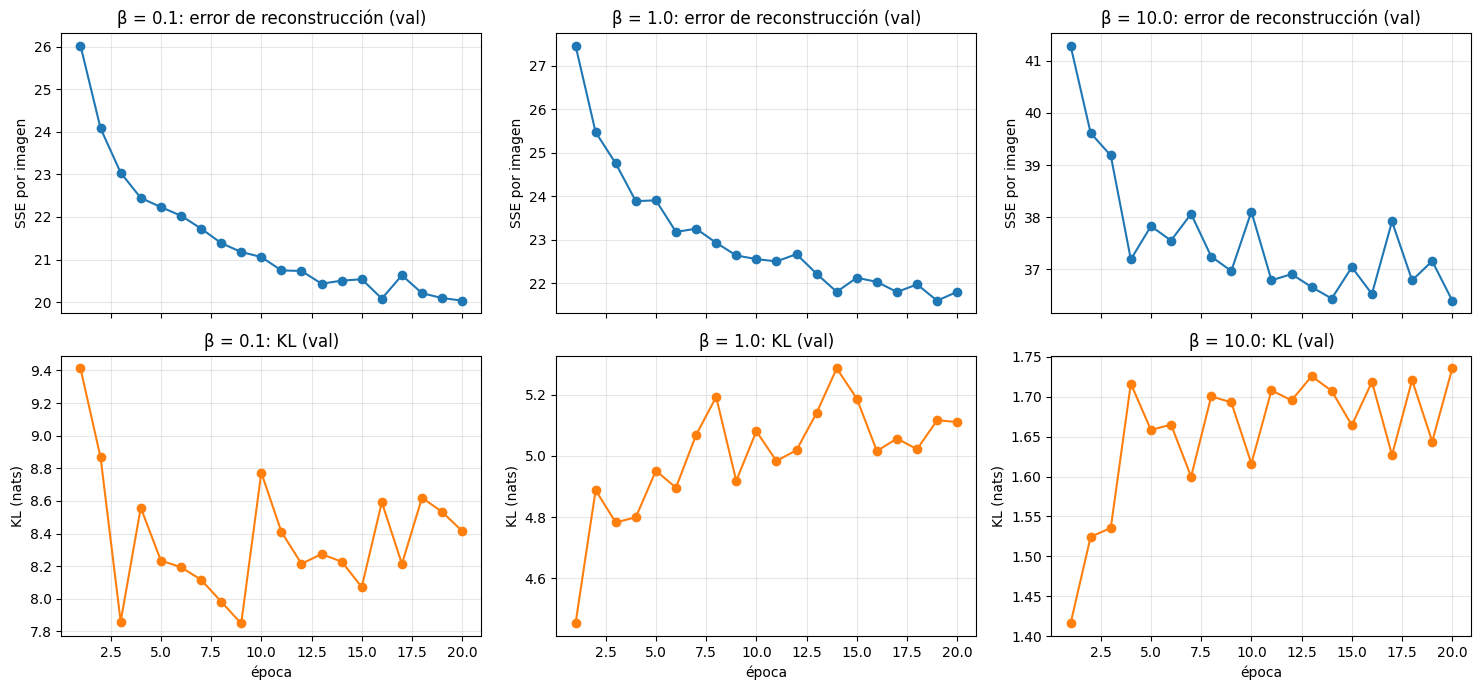

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
ep_axis = range(1, epochs + 1)
for j, b in enumerate(beta_values):
    axes[0, j].plot(ep_axis, hist[b]["val_rec"], marker="o", color="C0")
    axes[0, j].set_title(f"β = {b}: error de reconstrucción (val)")
    axes[0, j].set_ylabel("SSE por imagen")
    axes[1, j].plot(ep_axis, hist[b]["val_kl"], marker="o", color="C1")
    axes[1, j].set_title(f"β = {b}: KL (val)")
    axes[1, j].set_ylabel("KL (nats)"); axes[1, j].set_xlabel("época")
    for r in range(2): axes[r, j].grid(alpha=.3)
plt.tight_layout(); plt.show()

## Figuras

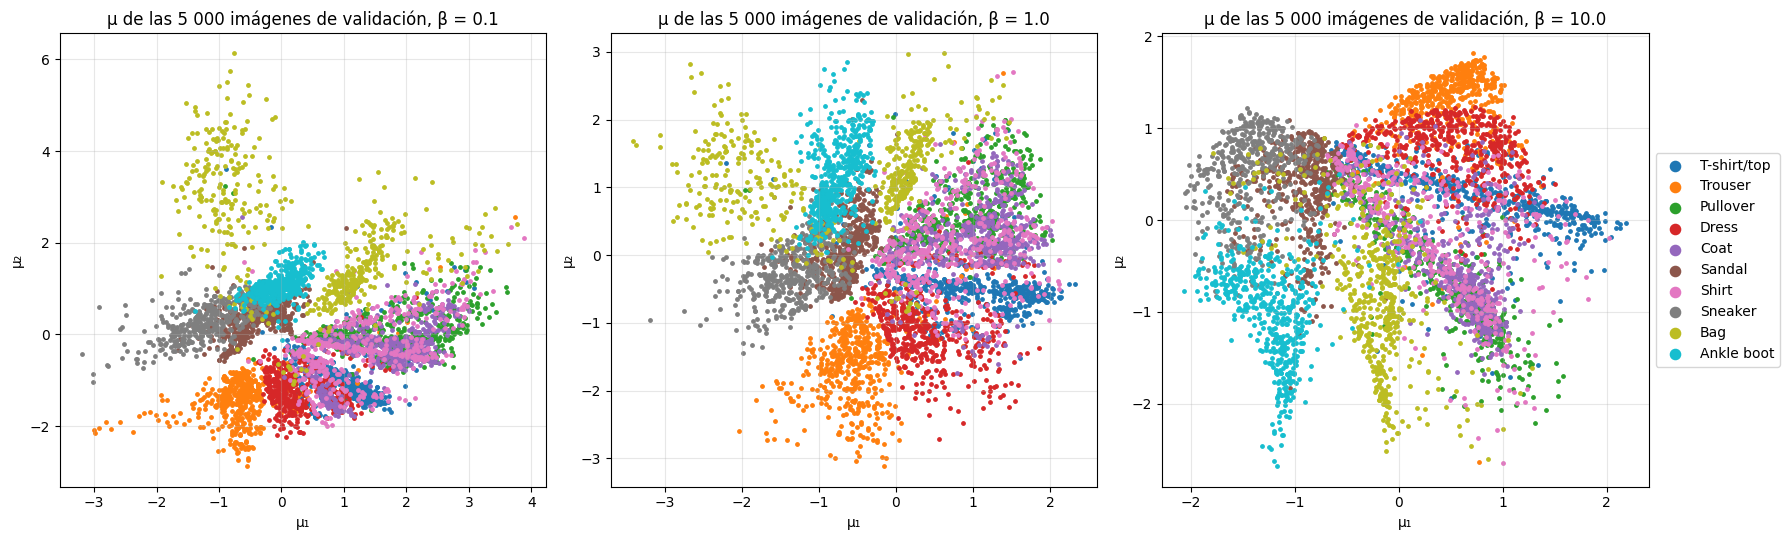

In [ ]:
@torch.no_grad()
def get_mu(model, X, bs=1000):
    model.eval()
    return torch.cat([model.encode(xb)[0] for xb in batches(X, bs, shuffle=False)]).cpu()

def mosaic(imgs, nrow, ncol):
    """imgs: (nrow*ncol, 784) en orden de filas -> imagen (nrow*28, ncol*28)."""
    return imgs.reshape(nrow, ncol, 28, 28).permute(0, 2, 1, 3).reshape(nrow * 28, ncol * 28)


fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, b in zip(axes, beta_values):
    mu_va = get_mu(models[b], X_va_f).numpy()
    for k in range(10):
        m = (y_va.numpy() == k)
        ax.scatter(mu_va[m, 0], mu_va[m, 1], s=6, color=plt.cm.tab10(k), label=CLASSES[k])
    ax.set_title(f"μ de las 5 000 imágenes de validación, β = {b}")
    ax.set_xlabel("μ₁"); ax.set_ylabel("μ₂"); ax.grid(alpha=.3)
axes[-1].legend(markerscale=3, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout(); plt.show()

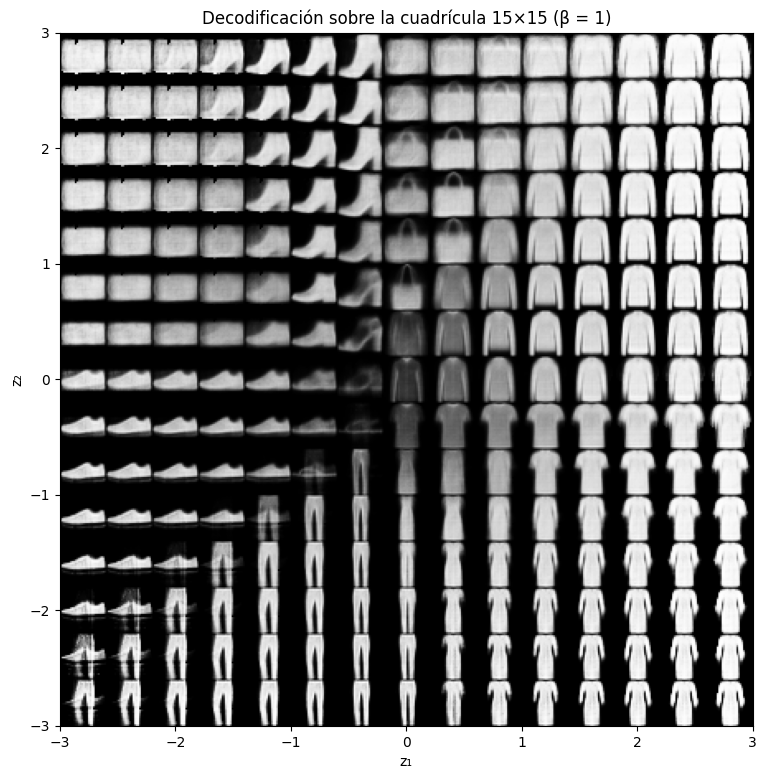

In [ ]:

model1 = models[1.0]
g = torch.linspace(-3, 3, 15)
zs = torch.stack([torch.stack([g[j], g[14 - i]]) for i in range(15) for j in range(15)]).to(device)
with torch.no_grad():
    grid_imgs = model1.decode(zs).cpu()
plt.figure(figsize=(9, 9))
plt.imshow(mosaic(grid_imgs, 15, 15), cmap="gray", extent=(-3, 3, -3, 3))
plt.xlabel("z₁"); plt.ylabel("z₂"); plt.title("Decodificación sobre la cuadrícula 15×15 (β = 1)")
plt.show()

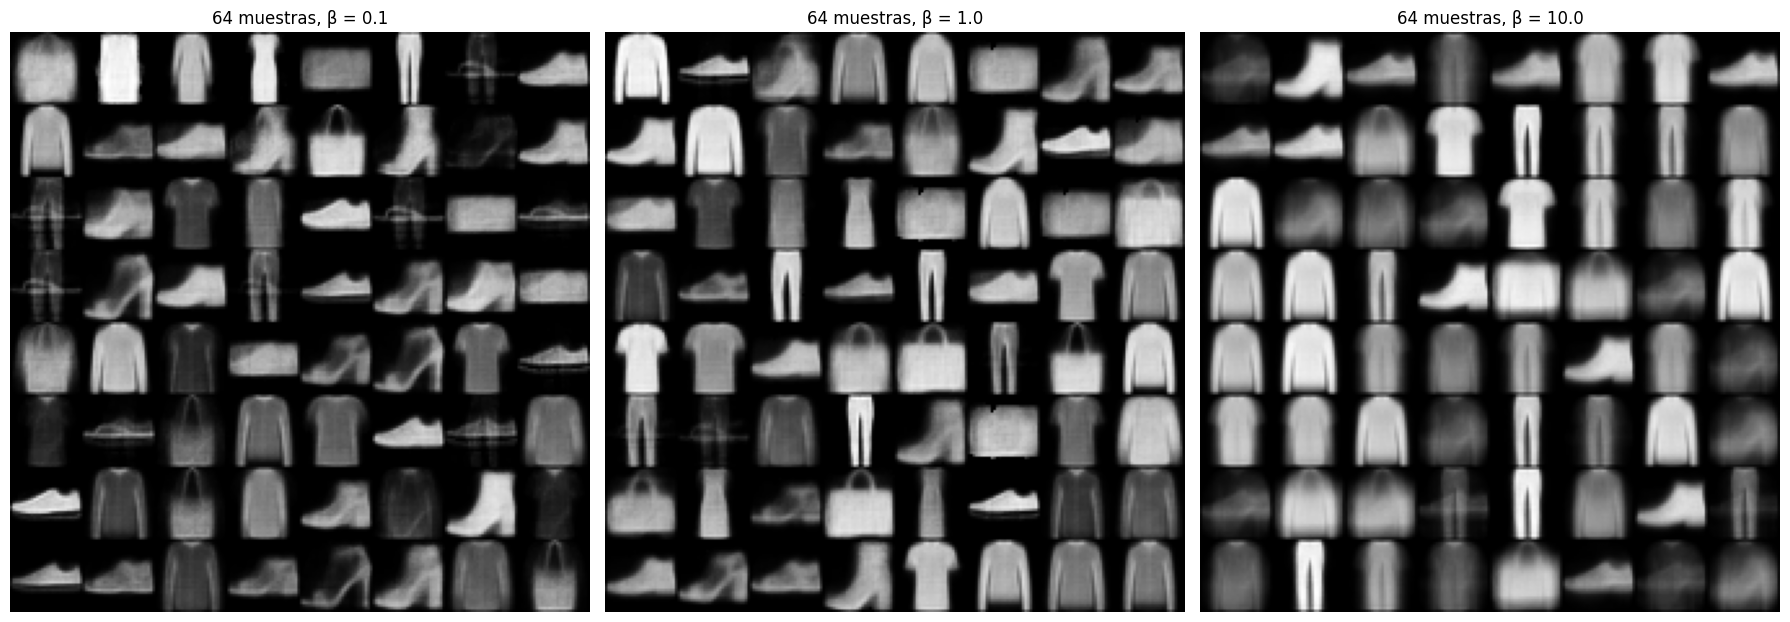

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(18, 6.2))
set_seed(SEED)
for ax, b in zip(axes, beta_values):
    with torch.no_grad():
        z = torch.randn(64, latent_dim, device=device)
        samp = models[b].decode(z).cpu()
    ax.imshow(mosaic(samp, 8, 8), cmap="gray"); ax.axis("off")
    ax.set_title(f"64 muestras, β = {b}")
plt.tight_layout(); plt.show()

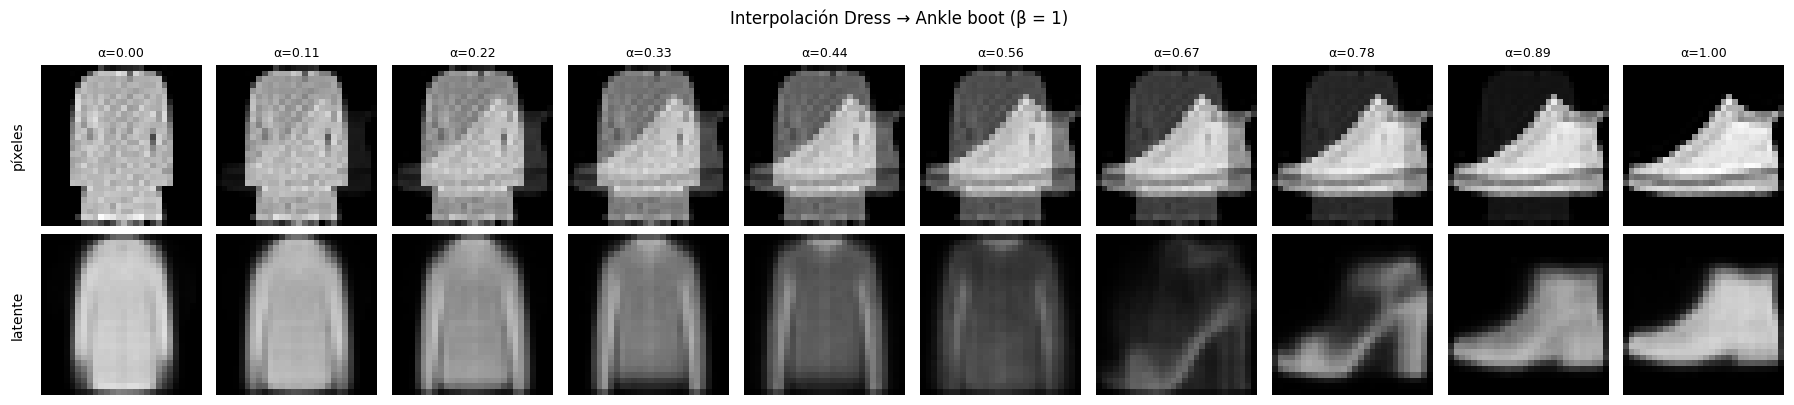

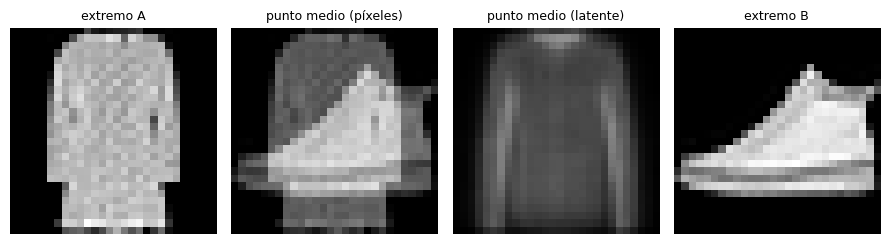

In [ ]:

cls_a, cls_b = 3, 9                                
ia = (y_va == cls_a).nonzero()[0].item()
ib = (y_va == cls_b).nonzero()[0].item()
x1, x2 = X_va_f[ia:ia + 1], X_va_f[ib:ib + 1]

alphas = torch.linspace(0, 1, 10, device=device)[:, None]    
with torch.no_grad():
    pix_interp = (1 - alphas) * x1 + alphas * x2
    mu1, _ = model1.encode(x1); mu2, _ = model1.encode(x2)
    lat_interp = model1.decode((1 - alphas) * mu1 + alphas * mu2)

fig, axes = plt.subplots(2, 10, figsize=(18, 4.2))
for k in range(10):
    axes[0, k].imshow(pix_interp[k].reshape(28, 28).cpu(), cmap="gray", vmin=0, vmax=1)
    axes[1, k].imshow(lat_interp[k].reshape(28, 28).cpu(), cmap="gray", vmin=0, vmax=1)
    for r in range(2):
        axes[r, k].axis("off")
    axes[0, k].set_title(f"α={alphas[k].item():.2f}", fontsize=9)
axes[0, 0].text(-0.1, 0.5, "píxeles", transform=axes[0, 0].transAxes, ha="right", va="center", rotation=90)
axes[1, 0].text(-0.1, 0.5, "latente", transform=axes[1, 0].transAxes, ha="right", va="center", rotation=90)
plt.suptitle(f"Interpolación {CLASSES[cls_a]} → {CLASSES[cls_b]} (β = 1)"); plt.tight_layout(); plt.show()

with torch.no_grad():
    mid_pix = 0.5 * x1 + 0.5 * x2
    mid_lat = model1.decode(0.5 * mu1 + 0.5 * mu2)
fig, axes = plt.subplots(1, 4, figsize=(9, 2.8))
for ax, im, tt in zip(axes, [x1, mid_pix, mid_lat, x2],
                      ["extremo A", "punto medio (píxeles)", "punto medio (latente)", "extremo B"]):
    ax.imshow(im.reshape(28, 28).cpu(), cmap="gray", vmin=0, vmax=1); ax.set_title(tt, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

##  Análisis

### (a) Tabla final de validación, KL en bits y capacidad de transmitir la clase

In [29]:
rows = []
for b in beta_values:
    kl = hist[b]["val_kl"][-1]
    rows.append({"β": b,
                 "Recon. val (SSE/img)": hist[b]["val_rec"][-1],
                 "KL val (nats)": kl,
                 "KL val (bits)": kl / math.log(2),
                 "log2(10) (bits)": math.log2(10)})
df_final = pd.DataFrame(rows)
display(df_final.round(3))

,β,Recon. val (SSE/img),KL val (nats),KL val (bits),log2(10) (bits)
0,0.1,20.034,8.415,12.141,3.322
1,1.0,21.810,5.110,7.372,3.322
2,10.0,36.402,1.736,2.504,3.322


**Respuesta 1.4(a).**

| β | Recon. val (SSE/img) | KL val (nats) | KL val (bits) |
|---|---|---|---|
| 0.1 | 20.03 | 8.415 | 12.14 |
| 1.0 | 21.81 | 5.110 | 7.37 |
| 10.0 | 36.40 | 1.736 | 2.50 |

Al subir β el modelo sacrifica reconstrucción (20.0 → 21.8 → 36.4) a cambio de una KL mucho menor (8.4 → 5.1 → 1.7 nats).

La KL media sobre los datos es una cota superior de la información mutua entre la imagen y el código: $I(x;z)=\mathbb{E}_x[D_{KL}(q(z|x)\Vert p(z))]-D_{KL}(q(z)\Vert p(z))\le \mathbb{E}_x[D_{KL}]$. Como la clase $y$ es función de la imagen, $I(y;z)\le I(x;z)\le \bar D_{KL}$. Identificar sin error una de 10 clases equiprobables requiere $H(y)=\log_2 10\approx3.32$ bits.

- **β = 10:** KL = 1.736 nats = **2.50 bits < 3.32 bits**. El código latente transmite, como máximo, 2.50 bits sobre la imagen y por tanto ≤ 2.50 bits sobre la clase: le faltan al menos ≈ 0.82 bits para poder identificarla de forma determinista. Heurísticamente, equivale a distinguir unas $2^{2.5}\approx5.7$ categorías equiprobables en lugar de 10.
- **β = 1 y β = 0.1:** 7.37 y 12.14 bits superan los 3.32 bits, así que en principio sí tienen capacidad para codificar la clase (y los diagramas muestran clases más separadas).
- **Contraste con el diagrama de β = 10:** es coherente con la cota. Las clases no están mezcladas al azar, sino agrupadas por categorías gruesas: pantalones (naranja) arriba, calzado a la izquierda (sneaker y sandalia arriba, ankle boot abajo), bolsos en una banda vertical central-inferior. En cambio camiseta, pullover, abrigo, camisa y vestido se solapan en una gran nube compartida. El código conserva información gruesa de categoría, pero no basta para separar clases parecidas.

### (b) Verificación de la KL en forma cerrada por Monte Carlo (β = 1)

In [ ]:
idx_img = 0
x_chk = X_va_f[idx_img:idx_img + 1]
with torch.no_grad():
    mu_c, lv_c = model1.encode(x_chk)
mu_c, lv_c = mu_c.double(), lv_c.double()
sigma_c = torch.exp(0.5 * lv_c)
D = mu_c.shape[1]

N_mc = 100_000
set_seed(SEED)
eps = torch.randn(N_mc, D, dtype=torch.float64, device=mu_c.device)
z = mu_c + sigma_c * eps                                                  

# log 
log_q = -0.5 * (((z - mu_c) / sigma_c) ** 2).sum(1) - torch.log(sigma_c).sum() - 0.5 * D * math.log(2 * math.pi)
log_p = -0.5 * (z ** 2).sum(1) - 0.5 * D * math.log(2 * math.pi)
d = log_q - log_p

#MC
kl_mc = d.mean().item()
se_mc = (d.std() / math.sqrt(N_mc)).item()                                  
kl_cf = kl_closed_form(mu_c, lv_c).item()
rel_err = abs(kl_mc - kl_cf) / kl_cf
print(f"mu = {mu_c.cpu().numpy().ravel()}, sigma = {sigma_c.cpu().numpy().ravel()}")
print(f"KL forma cerrada : {kl_cf:.6f} nats")
print(f"KL Monte Carlo   : {kl_mc:.6f} nats  (N = {N_mc})")
print(f"Error relativo   : {rel_err:.3e}")
print(f"Error estándar MC: {se_mc:.3e}  ->  |MC - cerrada| / SE = {abs(kl_mc - kl_cf) / se_mc:.2f}")

mu = [1.39784515 0.79153574], sigma = [0.13775255 0.08885363]
KL forma cerrada : 4.706747 nats
KL Monte Carlo   : 4.702702 nats  (N = 100000)
Error relativo   : 8.592e-04
Error estándar MC: 3.205e-03  ->  |MC - cerrada| / SE = 1.26


**Respuesta 1.4(b).** Para la imagen de validación 0 con el modelo de β = 1: $\mu=(1.398,\,0.792)$, $\sigma=(0.138,\,0.089)$.

| | KL (nats) |
|---|---|
| Forma cerrada | 4.706747 |
| Monte Carlo ($N=10^5$) | 4.702702 |
| Diferencia absoluta | 0.004045 |
| **Error relativo** | **8.6 × 10⁻⁴** (0.086 %) |

El promedio de $N=10^5$ muestras tiene error estándar $\mathrm{SE}=s/\sqrt N=3.2\times10^{-3}$ (con $s\approx1.01$ la desviación estándar de $\log q(z)-\log p(z)$). La diferencia observada equivale a $|{\rm MC}-{\rm cerrada}|/\mathrm{SE}=1.26$ errores estándar: **es compatible con la variabilidad esperada** de una estimación Monte Carlo de ese tamaño (un error sistemático, como un factor ½ o un signo mal puesto, daría cocientes de decenas). Por tanto la fórmula cerrada implementada es correcta.

### (c) Región no reconocible, interpolaciones, nitidez y relación con σ² = β/2

In [31]:
def sharpness(imgs_flat):
    """Magnitud media de la diferencia entre píxeles horizontalmente adyacentes."""
    im = imgs_flat.reshape(-1, 28, 28)
    return (im[:, :, 1:] - im[:, :, :-1]).abs().mean().item()

set_seed(SEED)
sharp = {"reales (1000 val)": sharpness(X_va_f[:1000])}
for b in beta_values:
    with torch.no_grad():
        z = torch.randn(1000, latent_dim, device=device)
        gen = models[b].decode(z)
    sharp[f"generadas β={b}"] = sharpness(gen)
df_sharp = pd.DataFrame({"nitidez": sharp}).round(4)
display(df_sharp)

,nitidez
reales (1000 val),0.0891
generadas β=0.1,0.0421
generadas β=1.0,0.0493
generadas β=10.0,0.0455


**Respuesta 1.4(c).**

**Región no reconocible (cuadrícula 15×15, β = 1).** La zona de transición cerca del origen y ligeramente a la izquierda, aproximadamente $z_1\in[-1,0.3]$, $z_2\in[-1,0.5]$, decodifica manchas oscuras y de bajo contraste, con siluetas fantasma superpuestas (restos de pantalón, bota y prenda superior a la vez). También son poco fiables las esquinas extremas ($|z|\gtrsim2.5$–3), p. ej. la esquina inferior izquierda, con rayas horizontales y formas superpuestas de pantalón y zapatilla, y la superior izquierda, con un rectángulo gris difuso.

*Explicación.* El término KL empuja a los posteriores $q(z|x)$ hacia $\mathcal N(0,I)$, por lo que las clases ocupan lóbulos separados y alrededor del origen sus colas se superponen. En esa frontera el decoder recibe objetivos contradictorios (el mismo $z$ puede venir de un pantalón, de una bota o de un suéter) y, al minimizar un error cuadrático, aprende su **promedio**: una imagen borrosa y oscura. En los bordes casi no hay códigos de entrenamiento (poca masa de prior), así que el decoder extrapola sin supervisión. El valor de β controla este equilibrio: con β = 0.1 (σ² = 0.05) los posteriores son estrechos, los lóbulos quedan más separados y los huecos entre ellos son más extensos y menos cubiertos; con β = 10 (σ² = 5) los posteriores se ensanchan y se solapan, el espacio se llena, pero cada $z$ mezcla muchas imágenes y todo sale más promediado. β = 1 está en un punto intermedio.

**Punto medio de las interpolaciones (Dress → Ankle boot, α = 0.5).**
- *En píxeles:* el resultado es un fundido cruzado: la silueta de la bota nítida y brillante superpuesta a la silueta tenue de la prenda, con ambas visibles a la vez. No es una imagen plausible de Fashion-MNIST (el promedio en píxeles se sale de la variedad de imágenes reales).
- *En el latente:* se obtiene **un solo objeto** coherente, pero borroso y de bajo contraste: un suéter tenue de manga larga. La trayectoria atraviesa otras clases (se ve un suéter, luego un tacón difuso en α ≈ 0.67 y por último la bota), en lugar de superponer ambas imágenes. Además, el extremo A decodificado ya es un suéter y no un vestido, porque con solo 2 dimensiones el modelo confunde estas clases.

*Por qué difieren:* en píxeles se promedian las intensidades de dos imágenes; en el latente se decodifica un punto, y el decoder siempre produce un objeto de la variedad que aprendió. Eso sí, la parte central de la ruta cae en la región de baja densidad descrita arriba, por eso el objeto sale tenue.

**Nitidez (media de |diferencia horizontal| entre píxeles adyacentes).**

| | nitidez | relación con reales |
|---|---|---|
| Reales (1000 val) | 0.0891 | 1.00 |
| Generadas β = 0.1 | 0.0421 | 0.47 |
| Generadas β = 1.0 | 0.0493 | 0.55 |
| Generadas β = 10 | 0.0455 | 0.51 |

Las muestras de los tres modelos tienen aproximadamente la mitad de la nitidez de las imágenes reales (47–55 %). **La relación no es monótona en β:** β = 1 es la más nítida y β = 0.1 la menos. Esta métrica no solo mide desenfoque, sino también contraste y contenido: con β = 0.1 muchas muestras con $z\sim\mathcal N(0,I)$ caen en huecos entre lóbulos y producen manchas tenues y oscuras con poco gradiente; con β = 10 las muestras son visiblemente más borrosas, pero son figuras brillantes y grandes, con bordes suavizados que aun así tienen gradiente apreciable. A simple vista (figura de 64 muestras), β = 10 es la más borrosa. Lo robusto es la comparación con las reales.

**Demostración de que $\mathcal L_\beta$ corresponde a $\sigma^2=\beta/2$.** Con decoder gaussiano $p(x|z)=\mathcal N(\hat x(z),\sigma^2 I_D)$, $D=784$:

$$-\log p(x|z)=\frac{\lVert x-\hat x\rVert^2}{2\sigma^2}+\frac D2\log(2\pi\sigma^2).$$

El ELBO negativo por imagen es $-\text{ELBO}=\frac{\lVert x-\hat x\rVert^2}{2\sigma^2}+\frac D2\log(2\pi\sigma^2)+D_{KL}$. Multiplicando por $2\sigma^2>0$ (no cambia el minimizador) y descartando la constante:

$$2\sigma^2(-\text{ELBO})\;\propto\;\lVert x-\hat x\rVert^2+2\sigma^2 D_{KL}.$$

Comparando con $\mathcal L_\beta=\lVert x-\hat x\rVert^2+\beta D_{KL}$ resulta $\beta=2\sigma^2$, es decir $\sigma^2=\beta/2$ (β = 0.1 → σ² = 0.05, σ ≈ 0.22; β = 1 → σ² = 0.5, σ ≈ 0.71; β = 10 → σ² = 5, σ ≈ 2.2). ∎

**Por qué las muestras salen borrosas.** Entrenar con $\mathcal L_\beta$ equivale a suponer ruido gaussiano de desviación $\sqrt{\beta/2}$ en cada píxel, valor que ya es grande frente al rango [0, 1] para β = 1 (σ ≈ 0.71). Un modelo que cree que el ruido es tan grande no necesita explicar los detalles finos: el óptimo para el error cuadrático es predecir la **media condicional** $\mathbb E[x|z]$, que promedia todas las imágenes compatibles con un código de solo 2 dimensiones y es suave. Además, al generar se usa directamente $\hat x(z)$ (la media), sin añadir el ruido de varianza σ², así que nunca se reintroduce textura. Los datos lo confirman: incluso con β = 0.1 (σ ≈ 0.22), la nitidez de las muestras es solo el 47 % de la real, y bajar β cien veces apenas cambia la métrica (0.042 frente a 0.049 con β = 1). Es decir, buena parte del desenfoque proviene de la combinación de pérdida cuadrática/decoder gaussiano y cuello de botella de 2 dimensiones, y no solo del valor de β. Subir β a 10 agrega, además, la pérdida de información (KL de solo 1.7 nats), lo que se ve en las muestras de la figura.

## Forward

In [ ]:
T = 1000
beta_start, beta_end = 1e-4, 0.02

#-1 1
X2_all = X_all * 2.0 - 1.0                       
X2_va  = X2_all[55000:]


betas_lin  = torch.linspace(beta_start, beta_end, T, dtype=torch.float64)
alphas_lin = 1.0 - betas_lin
abar_lin   = torch.cumprod(alphas_lin, dim=0)

def q_sample(x0, t, eps, abar):
    """x_t = sqrt(abar_t) x0 + sqrt(1 - abar_t) eps. t: LongTensor (B,) con valores en 1..T."""
    ab = abar.to(device=x0.device, dtype=x0.dtype)[t.to(x0.device) - 1]
    ab = ab.reshape(-1, *([1] * (x0.dim() - 1)))
    return ab.sqrt() * x0 + (1.0 - ab).sqrt() * eps

print("beta_1 =", betas_lin[0].item(), "| beta_T =", betas_lin[-1].item(),
      "| abar_T =", abar_lin[-1].item())

beta_1 = 0.0001 | beta_T = 0.02 | abar_T = 4.0358297653756754e-05


## Verificación empírica de la fórmula cerrada

In [ ]:
set_seed(SEED)
N_copies, t_check = 5000, 300
x0_fix = X2_va[0].to(device)                               
x = x0_fix.expand(N_copies, 28, 28).clone()

for s in range(t_check):                                   
    eps_s = torch.randn_like(x)                             
    x = alphas_lin[s].sqrt().item() * x + betas_lin[s].sqrt().item() * eps_s

x64 = x.double()
emp_mean = x64.mean(0)
emp_var  = x64.var(0, unbiased=True)
abar_t   = abar_lin[t_check - 1].item()
th_mean  = math.sqrt(abar_t) * x0_fix.double()
th_var   = 1.0 - abar_t

err_mean = (emp_mean - th_mean).abs()
se_mean  = math.sqrt(th_var / N_copies)                       
z_scores = err_mean / se_mean
print(f"abar_300 = {abar_t:.6f} | var teórica = {th_var:.6f}")
print(f"Error máximo absoluto de la media : {err_mean.max().item():.5f}")
print(f"Error estándar esperado  sqrt(var/N) = {se_mean:.5f}")
print(f"max |error| / SE = {z_scores.max().item():.2f}   (esperado ≈ 3.2 para el máximo de 784 píxeles)")
print(f"Fracción de píxeles con |error| < 2·SE = {(z_scores < 2).double().mean().item():.3f}  (esperado ≈ 0.954)")
print(f"Varianza empírica promedio = {emp_var.mean().item():.6f}  vs teórica = {th_var:.6f}")
print(f"Error estándar de la varianza (1 píxel) = {th_var * math.sqrt(2 / (N_copies - 1)):.5f}; "
      f"error estándar del promedio sobre 784 píxeles = {th_var * math.sqrt(2 / (N_copies - 1)) / math.sqrt(784):.6f}")

abar_300 = 0.396420 | var teórica = 0.603580
Error máximo absoluto de la media : 0.03538
Error estándar esperado  sqrt(var/N) = 0.01099
max |error| / SE = 3.22   (esperado ≈ 3.2 para el máximo de 784 píxeles)
Fracción de píxeles con |error| < 2·SE = 0.954  (esperado ≈ 0.954)
Varianza empírica promedio = 0.604062  vs teórica = 0.603580
Error estándar de la varianza (1 píxel) = 0.01207; error estándar del promedio sobre 784 píxeles = 0.000431


**Respuesta 2.2.** Con $N=5000$ copias y $t=300$ ($\bar\alpha_{300}=0.3964$, varianza teórica $1-\bar\alpha_{300}=0.6036$):

- **Error máximo absoluto de la media:** 0.03538.
- **Error estándar esperado** de un promedio de 5000 muestras: $\mathrm{SE}=\sqrt{0.6036/5000}=0.01099$.
- **Cociente máximo:** $0.03538/0.01099=3.22$. Para el máximo de 784 píxeles independientes se espera ≈ 3.2 (la probabilidad de $|z|>3.2$ es ≈ 0.0014, y 784 × 0.0014 ≈ 1.1 píxeles). Además, el 95.4 % de los píxeles queda dentro de 2 SE (esperado 95.4 %).
- **Varianza empírica promedio:** 0.60406 frente a la teórica 0.60358. La diferencia (4.8 × 10⁻⁴) equivale a 1.1 veces el error estándar del promedio sobre 784 píxeles (4.3 × 10⁻⁴).

**Conclusión:** el error de la media es exactamente el esperado por el muestreo de 5000 copias, sin sesgo, y la varianza coincide dentro de su error estándar. La fórmula cerrada es consistente con el proceso paso a paso (suma de gaussianas independientes, con $\bar\alpha_t=\prod\alpha_s$).

## Task 2.3 — Visualización, SNR y tiempos clave

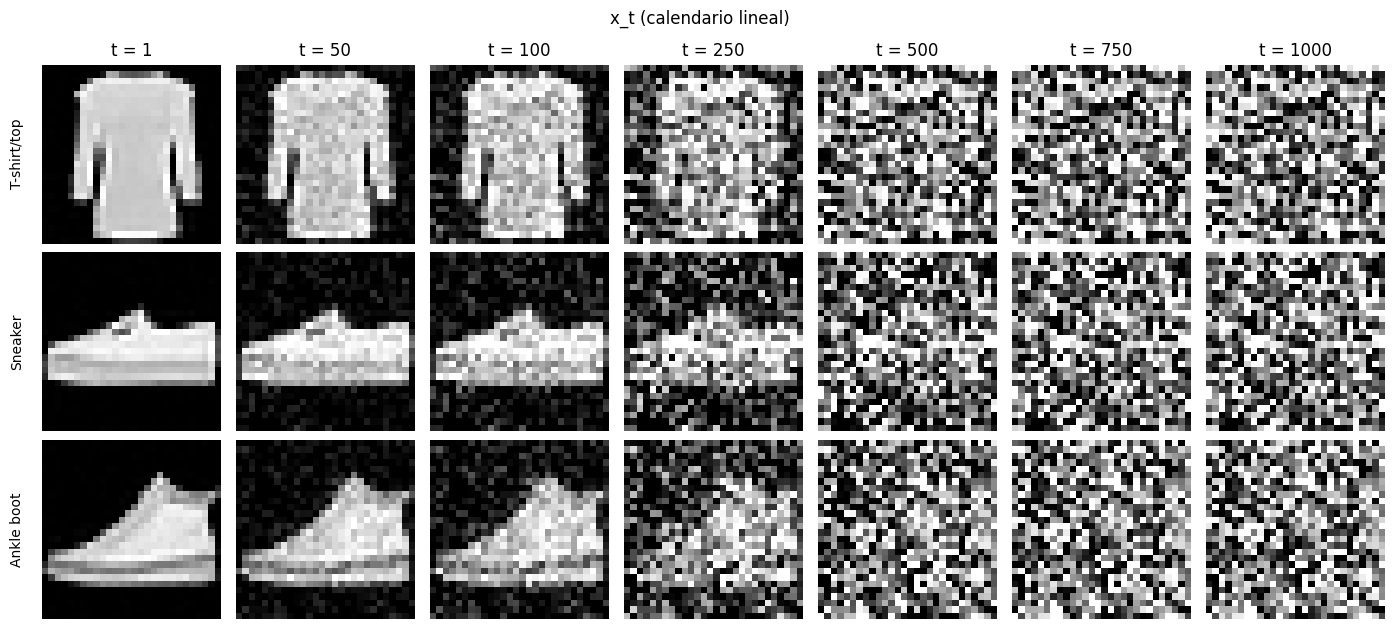

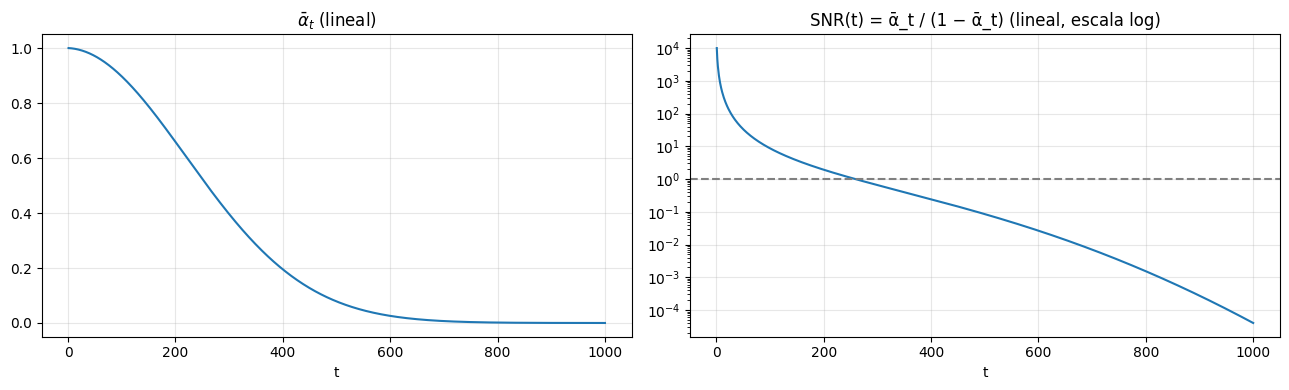

Primer t con SNR(t) < 1      : 260
Primer t con abar_t < 0.01   : 674


In [ ]:
set_seed(SEED)
ts_vis = [1, 50, 100, 250, 500, 750, 1000]
cls_vis = [0, 7, 9]                                        
fig, axes = plt.subplots(3, len(ts_vis), figsize=(14, 6.4))
for r, c in enumerate(cls_vis):
    i = (y_va == c).nonzero()[0].item()
    x0 = X2_va[i]
    e = torch.randn_like(x0)                                 
    for k, t in enumerate(ts_vis):
        xt = q_sample(x0[None], torch.tensor([t]), e[None], abar_lin)[0]
        axes[r, k].imshow(xt.clamp(-1, 1), cmap="gray", vmin=-1, vmax=1); axes[r, k].axis("off")
        if r == 0: axes[r, k].set_title(f"t = {t}")
    axes[r, 0].text(-0.1, 0.5, CLASSES[c], transform=axes[r, 0].transAxes, ha="right", va="center", rotation=90)
plt.suptitle("x_t (calendario lineal)"); plt.tight_layout(); plt.show()

t_axis = np.arange(1, T + 1)
snr_lin = abar_lin / (1.0 - abar_lin)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(t_axis, abar_lin.numpy()); axes[0].set_title(r"$\bar\alpha_t$ (lineal)"); axes[0].set_xlabel("t"); axes[0].grid(alpha=.3)
axes[1].semilogy(t_axis, snr_lin.numpy()); axes[1].axhline(1, color="gray", ls="--")
axes[1].set_title("SNR(t) = ᾱ_t / (1 − ᾱ_t) (lineal, escala log)"); axes[1].set_xlabel("t"); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

t_snr1  = int((snr_lin < 1).nonzero()[0].item()) + 1
t_abar1 = int((abar_lin < 0.01).nonzero()[0].item()) + 1
print("Primer t con SNR(t) < 1      :", t_snr1)
print("Primer t con abar_t < 0.01   :", t_abar1)

**Respuesta 2.3.** Con el calendario lineal: el primer $t$ con SNR(t) < 1 (equivalente a $\bar\alpha_t<0.5$) es **t = 260**, y el primer $t$ con $\bar\alpha_t<0.01$ es **t = 674**. En las figuras se aprecia que hacia t ≈ 250 ya no se distingue bien la prenda, y desde t ≈ 750 la imagen es ruido prácticamente puro.

## Segundo calendario

**Base en la literatura:** calendario coseno de Nichol & Dhariwal, *Improved Denoising Diffusion Probabilistic Models* (ICML 2021): $\bar\alpha_t=f(t)/f(0)$, $f(t)=\cos^2\!\Big(\frac{t/T+s}{1+s}\cdot\frac\pi2\Big)$, con $s=0.008$.

**Modificación propia:** el coseno original llega a $\bar\alpha_T\approx0$ (SNR = 0 exacto), lo que obliga a recortar $\beta_T$ y deja los últimos pasos como ruido puro. Aquí se **trunca** el tiempo: se evalúa $f$ en $r\,t/T$ con $r<1$ elegido para que $\bar\alpha_T=10^{-4}$ exactamente (cumple $<10^{-3}$) y todos los $\beta_t$ salen de $\beta_t=1-\bar\alpha_t/\bar\alpha_{t-1}$, sin necesidad de recortes.

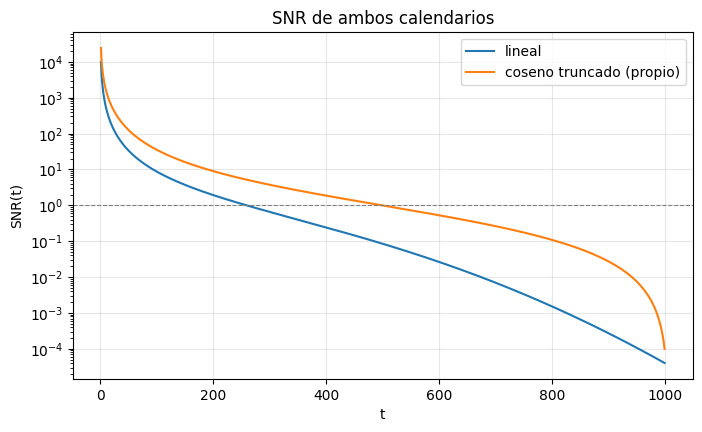

,calendario,abar_T,primer t con SNR<1,beta_min,beta_max
0,lineal,0.00004,260,0.000100,0.020000
1,coseno truncado,0.00010,500,0.000041,0.250176


In [ ]:
s_cos, abar_T_target = 0.008, 1e-4
f_cos = lambda u: torch.cos(((u + s_cos) / (1 + s_cos)) * math.pi / 2) ** 2


f0 = f_cos(torch.tensor(0.0, dtype=torch.float64)).item()
r_trunc = math.acos(math.sqrt(abar_T_target * f0)) * 2 / math.pi * (1 + s_cos) - s_cos

t_grid = torch.arange(0, T + 1, dtype=torch.float64)
abar_full = f_cos(r_trunc * t_grid / T) / f_cos(torch.tensor(0.0, dtype=torch.float64))
betas_cos  = 1.0 - abar_full[1:] / abar_full[:-1]
alphas_cos = 1.0 - betas_cos
abar_cos   = torch.cumprod(alphas_cos, dim=0)
assert (betas_cos > 0).all() and (betas_cos < 1).all(), "beta_t debe estar en (0,1)"
assert abar_cos[-1] < 1e-3, "abar_T debe ser < 1e-3"
snr_cos = abar_cos / (1.0 - abar_cos)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogy(t_axis, snr_lin.numpy(), label="lineal")
ax.semilogy(t_axis, snr_cos.numpy(), label="coseno truncado (propio)")
ax.axhline(1, color="gray", ls="--", lw=.8)
ax.set_xlabel("t"); ax.set_ylabel("SNR(t)"); ax.set_title("SNR de ambos calendarios"); ax.legend(); ax.grid(alpha=.3)
plt.show()

df_sched = pd.DataFrame({
    "calendario": ["lineal", "coseno truncado"],
    "abar_T": [abar_lin[-1].item(), abar_cos[-1].item()],
    "primer t con SNR<1": [int((snr_lin < 1).nonzero()[0]) + 1, int((snr_cos < 1).nonzero()[0]) + 1],
    "beta_min": [betas_lin.min().item(), betas_cos.min().item()],
    "beta_max": [betas_lin.max().item(), betas_cos.max().item()],
})
display(df_sched)

**Respuesta 2.4.**

| Calendario | $\bar\alpha_T$ | Primer $t$ con SNR < 1 | $\beta_{\min}$ | $\beta_{\max}$ |
|---|---|---|---|---|
| Lineal | 4.04 × 10⁻⁵ | 260 | 1 × 10⁻⁴ | 0.020 |
| Coseno truncado (propio) | 1.00 × 10⁻⁴ | 500 | 4.1 × 10⁻⁵ | 0.250 |

Ambos cumplen $\bar\alpha_T<10^{-3}$ y $\beta_t\in(0,1)$. En el calendario propio el SNR baja de forma mucho más gradual (SNR = 1 se alcanza en t = 500, frente a 260 del lineal).

## Análisis

### (a) Cálculo a mano de $\bar\alpha_T$ para el calendario lineal

Con $\log\bar\alpha_T=\sum_{t=1}^{T}\log(1-\beta_t)\approx-\sum\beta_t-\tfrac12\sum\beta_t^2$, $\beta_1=10^{-4}$, $\beta_T=0.02$, $T=1000$:

1. **Primera suma (aritmética):** $\sum_t\beta_t=\dfrac{T(\beta_1+\beta_T)}{2}=\dfrac{1000\,(10^{-4}+0.02)}{2}=10.05$.
2. **Segunda suma (aproximación integral):** con $\beta(u)=\beta_1+(\beta_T-\beta_1)u$, $u\in[0,1]$:
   $\sum_t\beta_t^2\approx T\!\int_0^1\!\beta(u)^2du=\dfrac{T(\beta_1^2+\beta_1\beta_T+\beta_T^2)}{3}=\dfrac{1000\,(10^{-8}+2\times10^{-6}+4\times10^{-4})}{3}\approx0.1340$, por lo que $\tfrac12\sum\beta_t^2\approx0.0670$.
3. **Resultado:** $\log\bar\alpha_T\approx-10.05-0.0670=-10.117\;\Rightarrow\;\bar\alpha_T\approx e^{-10.117}\approx4.04\times10^{-5}$.

(El siguiente término del desarrollo, $-\tfrac13\sum\beta_t^3\approx-6.7\times10^{-4}$, es despreciable.) La celda siguiente compara con el valor numérico.

In [36]:
S1_exact = betas_lin.sum().item()
S2_exact = (betas_lin ** 2).sum().item()
S1_hand = T * (beta_start + beta_end) / 2
S2_hand = T * (beta_start**2 + beta_start * beta_end + beta_end**2) / 3
abar_hand = math.exp(-S1_hand - 0.5 * S2_hand)
abar_code = abar_lin[-1].item()
abar_code_log = math.exp(torch.log1p(-betas_lin).sum().item())
print(f"Σβ      : a mano {S1_hand:.4f} | código {S1_exact:.4f}")
print(f"Σβ²     : a mano {S2_hand:.5f} | código {S2_exact:.5f}")
print(f"abar_T  : aproximación a mano {abar_hand:.4e} | código (cumprod) {abar_code:.4e} | Σlog(1-β) {abar_code_log:.4e}")
print(f"Error relativo de la aproximación: {abs(abar_hand - abar_code) / abar_code:.2e}")

Σβ      : a mano 10.0500 | código 10.0500
Σβ²     : a mano 0.13400 | código 0.13407
abar_T  : aproximación a mano 4.0387e-05 | código (cumprod) 4.0358e-05 | Σlog(1-β) 4.0358e-05
Error relativo de la aproximación: 7.12e-04


**Respuesta 2.5(a).** La aproximación a mano da $\bar\alpha_T\approx4.039\times10^{-5}$ y el código (producto acumulado) da $4.036\times10^{-5}$: error relativo de 7.1 × 10⁻⁴ (0.07 %). Esa diferencia viene principalmente del término de tercer orden omitido, $-\tfrac13\sum\beta_t^3\approx-6.7\times10^{-4}$ en $\log\bar\alpha_T$, y en mucha menor medida de la aproximación integral de $\sum\beta_t^2$ (0.13400 frente a 0.13407 exacto).

### (b) Pasos con SNR ∈ [0.01, 100] y eficiencia de los calendarios

In [37]:
def regime_counts(snr):
    return {"SNR<0.01 (x_t≈ε)": int((snr < 0.01).sum()),
            "SNR∈[0.01,100]": int(((snr >= 0.01) & (snr <= 100)).sum()),
            "SNR>100 (x_t≈x0)": int((snr > 100).sum())}
df_reg = pd.DataFrame({"lineal": regime_counts(snr_lin), "coseno truncado": regime_counts(snr_cos)}).T
display(df_reg)

,SNR<0.01 (x_t≈ε),"SNR∈[0.01,100]",SNR>100 (x_t≈x0)
lineal,326,647,27
coseno truncado,58,886,56


**Respuesta 2.5(b).**

| Calendario | SNR < 0.01 | SNR ∈ [0.01, 100] | SNR > 100 |
|---|---|---|---|
| Lineal | 326 | **647** | 27 |
| Coseno truncado | 58 | **886** | 56 |

- **SNR ≪ 0.01 ($x_t\approx\epsilon$).** Predecir $\epsilon$ es casi trivial: basta con devolver $x_t$ (la señal es despreciable). El error ya es ≈ 0 y no hay estructura de imagen que aprender, así que estos pasos aportan casi nada al aprendizaje aunque se muestreen con la misma frecuencia que los demás.
- **SNR ≫ 100 ($x_t\approx x_0$).** Aquí el ruido es una perturbación diminuta sobre la imagen. Predecir $\epsilon$ exige separar un ruido de amplitud $\sqrt{1-\bar\alpha_t}$ muy pequeña de una imagen desconocida: cualquier error al estimar $x_0$ se amplifica por $1/\sqrt{1-\bar\alpha_t}$. La tarea es difícil y ruidosa, y lo que se aprende son detalles casi imperceptibles, con poco aporte a la calidad global de la muestra.
- **SNR ∈ [0.01, 100].** Señal y ruido son comparables: la red tiene que usar la estructura de la imagen para separarlos. Aquí se concentra el aprendizaje útil.

Con $t$ sorteado uniformemente, la fracción de iteraciones útiles es (pasos con SNR ∈ [0.01,100]) / T: **64.7 % con el calendario lineal frente a 88.6 % con el coseno truncado**. El lineal desperdicia el 32.6 % de los pasos (326) en la zona de ruido casi puro, frente al 5.8 % del coseno. Por tanto, **el calendario coseno truncado es más eficiente**. (Tiene algo más de pasos con SNR > 100, 56 frente a 27, pero muchos menos en el régimen trivial.)

### (c) Varianza global de $x_t$

**Demostración.** Sea $x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon$ con $\epsilon\sim\mathcal{N}(0,I)$ independiente de $x_0$. Para la varianza global (todos los píxeles de todas las imágenes, tomados como una sola población):

$$\mathrm{Var}(x_t)=\bar\alpha_t\,\mathrm{Var}(x_0)+(1-\bar\alpha_t)\,\mathrm{Var}(\epsilon)+2\sqrt{\bar\alpha_t(1-\bar\alpha_t)}\,\mathrm{Cov}(x_0,\epsilon).$$

Como $\epsilon$ es independiente de $x_0$, $\mathrm{Cov}(x_0,\epsilon)=0$, y $\mathrm{Var}(\epsilon)=1$, por lo que

$$\mathrm{Var}(x_t)=\bar\alpha_t\,\mathrm{Var}(x_0)+(1-\bar\alpha_t).\;\;\blacksquare$$

In [ ]:
set_seed(SEED)
X2_train = X2_all                                           
var0 = X2_train.double().var(unbiased=False).item()
print(f"Var(x0) sobre entrenamiento en [-1,1]: {var0:.6f}")

rows = []
for t in [1, 250, 500, 1000]:
    e = torch.randn_like(X2_train)
    tt = torch.full((X2_train.shape[0],), t, dtype=torch.long)
    xt = q_sample(X2_train, tt, e, abar_lin)
    emp = xt.double().var(unbiased=False).item()
    ab = abar_lin[t - 1].item()
    pred = ab * var0 + (1 - ab)
    rows.append({"t": t, "abar_t": ab, "Var empírica": emp, "Var predicha": pred, "dif. abs.": abs(emp - pred)})
    del e, xt
display(pd.DataFrame(rows))

Var(x0) sobre entrenamiento en [-1,1]: 0.498504


,t,abar_t,Var empírica,Var predicha,dif. abs.
0,1,0.999900,0.498550,0.498555,0.000005
1,250,0.524085,0.737244,0.737174,0.000071
2,500,0.078587,0.960608,0.960589,0.000020
3,1000,0.000040,1.000223,0.999980,0.000243


**Respuesta 2.5(c).** $\mathrm{Var}(x_0)=0.498504$ sobre el conjunto de entrenamiento escalado a [−1, 1].

| $t$ | $\bar\alpha_t$ | Var empírica | Var predicha | dif. abs. |
|---|---|---|---|---|
| 1 | 0.999900 | 0.498550 | 0.498555 | 5 × 10⁻⁶ |
| 250 | 0.524085 | 0.737244 | 0.737174 | 7.1 × 10⁻⁵ |
| 500 | 0.078587 | 0.960608 | 0.960589 | 2.0 × 10⁻⁵ |
| 1000 | 0.000040 | 1.000223 | 0.999980 | 2.4 × 10⁻⁴ |

Las diferencias son del orden del ruido de muestreo: con ≈ 4.7 × 10⁷ valores, el error estándar de una varianza estimada es ≈ $\sqrt{2/N}\approx2\times10^{-4}$ (para $t=1000$, la diferencia de 2.4 × 10⁻⁴ es ≈ 1.2 errores estándar). Se confirma numéricamente $\mathrm{Var}(x_t)=\bar\alpha_t\mathrm{Var}(x_0)+(1-\bar\alpha_t)$.

**Varianza de $x_T$.** Con $\bar\alpha_T\approx4\times10^{-5}$ se predice $\mathrm{Var}(x_T)=0.99998\approx1$ (empírica: 1.0002). Es necesario que sea ≈ 1, y que la media sea ≈ 0 (pues $\sqrt{\bar\alpha_T}\,\mathbb E[x_0]\approx0$), porque la generación parte de $x_T\sim\mathcal N(0,I)$: la distribución que el modelo ve en entrenamiento en $t=T$ debe coincidir con la que se usa como punto de partida al muestrear. Si $\mathrm{Var}(x_T)\neq1$ (o si quedara señal residual por $\bar\alpha_T$ no despreciable), habría un desajuste entre el $x_T$ de entrenamiento y el $\mathcal N(0,I)$ de generación, y la cadena inversa arrancaría desde una entrada fuera de la distribución para la que fue entrenada.